# Lab 0 (Parcial 2) — Trabajando con secuencias: modelos autorregresivos

## Objetivos

En una secuencia, cada valor depende de los anteriores: la temperatura de hoy se parece a la de ayer y la siguiente letra de una palabra depende de las que ya hemos leído. Un **modelo autorregresivo (AR)** aprovecha esa dependencia: predice el siguiente valor $x_t$ a partir de los $\tau$ valores anteriores $x_{t-\tau},\dots,x_{t-1}$. Con una ventana de longitud fija, el problema se convierte en una **regresión supervisada** normal.

El cuaderno tiene dos partes:

* **Parte A — cuaderno base.** Se ejecuta y comenta el cuaderno proporcionado (`P0_VF.ipynb`): datos sintéticos (seno + ruido), regresión lineal autorregresiva con $\tau=4$, predicción a un paso, a varios pasos y a $k$ pasos.
* **Parte B — ejercicios.**
  1. Variar el número de observaciones anteriores $\tau$, graficar el error en función de $\tau$ y justificar el valor óptimo.
  2. Con el $\tau$ elegido, comparar la predicción a distintos horizontes $k$ graficando el error.
  3. Repetir el análisis con datos reales (temperaturas mínimas diarias y, como complemento, cotización de IBM), con MAE y MSE.
  4. Teoría: modelos autorregresivos frente a modelos autorregresivos latentes, con un ejemplo que necesite variables latentes.

Todas las métricas se calculan sobre datos **no usados en el entrenamiento** y, cuando el resultado depende del azar (ruido de los datos, inicialización y orden de los lotes), se promedian varias semillas.

## 1. Preparación del entorno

En Colab basta con ejecutar `!pip install d2l==1.0.0a0`. En local se usa un entorno con `torch`, `d2l==1.0.0a0` (basta instalarlo con `--no-deps`; ver `Parcial-2/requirements.txt`), `pandas` y `matplotlib`. La celda localiza la carpeta con los datos tanto si el cuaderno se abre desde `Lab-0` como desde la raíz del repositorio.

In [1]:
%matplotlib inline
# !pip install d2l==1.0.0a0        # descomentar en Colab
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from d2l import torch as d2l

SEED = 0


def fijar_semilla(semilla=SEED):
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)


DATA_DIR = None
for candidato in (Path.cwd(), Path.cwd() / 'Lab-0',
                  Path.cwd() / 'Parcial-2' / 'Lab-0-Introduccion-a-NLP' / 'Lab-0'):
    if (candidato / 'ibm.us.txt').exists():
        DATA_DIR = candidato
        break
if DATA_DIR is None:
    raise FileNotFoundError('No se encuentran ibm.us.txt ni daily-min-temperatures.csv')

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print('PyTorch', torch.__version__, '| datos en', DATA_DIR.name)

PyTorch 2.15.0 | datos en Lab-0


# Parte A — Cuaderno base comentado

## 2. Datos sintéticos: un seno con ruido

Se generan $T=1000$ puntos de $x_t=\sin(0{,}01\,t)+\varepsilon_t$ con $\varepsilon_t\sim\mathcal N(0,\,0{,}2^2)$. La parte $\sin(0{,}01\,t)$ es la **señal** (predecible a partir del pasado) y $\varepsilon_t$ es **ruido blanco** (independiente de todo lo anterior, imposible de predecir). Su varianza, $0{,}2^2=0{,}04$, es por tanto el **MSE mínimo alcanzable** por cualquier modelo: lo usaremos como suelo de referencia.

Parámetros de la clase `Data`: `batch_size=16`, `T=1000` (longitud de la serie), `num_train=600` (los primeros 600 ejemplos entrenan, el resto se usa para evaluar) y `tau=4` (cada predicción usa los 4 valores anteriores: modelo de Markov de orden 4).

<class 'torch.Tensor'> <class 'torch.Tensor'> torch.Size([1000])


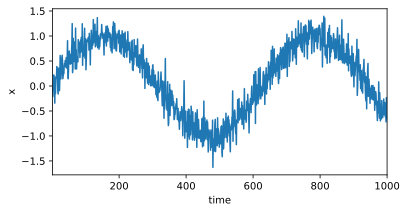

In [2]:
fijar_semilla()


class Data(d2l.DataModule):
    def __init__(self, batch_size=16, T=1000, num_train=600, tau=4):
        self.save_hyperparameters()
        self.time = torch.arange(1, T + 1, dtype=torch.float32)
        self.x = torch.sin(0.01 * self.time) + torch.randn(T) * 0.2


data = Data()
print(type(data.time), type(data.x), data.x.shape)
d2l.plot(data.time, data.x, 'time', 'x', xlim=[1, 1000], figsize=(6, 3))

## 3. De la serie a un problema supervisado: ventanas deslizantes

Con una ventana de longitud $\tau$, cada instante $t$ da un ejemplo con **características** $\mathbf x_t=[x_{t-\tau},\dots,x_{t-1}]$ y **etiqueta** $y=x_t$. `get_dataloader` construye la matriz de características apilando $\tau$ copias desplazadas de la serie: la columna $i$ es `x[i : T-tau+i]`, de modo que la fila $j$ contiene `x[j], …, x[j+tau-1]` y su etiqueta es `x[j+tau]`. Así se obtienen $T-\tau=996$ ejemplos; los 600 primeros entrenan y los 396 restantes se usan para evaluar.

In [3]:
@d2l.add_to_class(Data)
def get_dataloader(self, train):
    features = [self.x[i : self.T-self.tau+i] for i in range(self.tau)]
    self.features = torch.stack(features, 1)
    self.labels = self.x[self.tau:].reshape((-1, 1))
    i = slice(0, self.num_train) if train else slice(self.num_train, None)
    return self.get_tensorloader([self.features, self.labels], train, i)


data.get_dataloader(train=True)
print('features:', tuple(data.features.shape), '| labels:', tuple(data.labels.shape))
print('fila 0  :', data.features[0].numpy().round(3), '-> etiqueta', data.labels[0].item().__round__(3))
print('x[0:5]  :', data.x[:5].numpy().round(3))

features: (996, 4) | labels: (996, 1)
fila 0  : [-0.215 -0.21  -0.02  -0.047] -> etiqueta 0.22
x[0:5]  : [-0.215 -0.21  -0.02  -0.047  0.22 ]


La fila 0 contiene `x[0..3]` y su etiqueta es `x[4]`: la ventana de 4 valores predice el quinto, exactamente el esquema de instancias de las diapositivas (instancia 1 = posiciones $1..L$ → salida $L+1$).

## 4. Modelo: regresión lineal autorregresiva

`d2l.LinearRegression` es una capa lineal con una salida, $\hat x_t=w_1x_{t-\tau}+\dots+w_\tau x_{t-1}+b$, entrenada con **SGD** ($\eta=0{,}01$), pérdida **MSE** y lotes de 16. Es la versión de orden $\tau$ de la autorregresión lineal de las diapositivas, $\min_{c,\phi}\sum_t\big(Y_t-(c+\phi_1Y_{t-1}+\dots+\phi_\tau Y_{t-\tau})\big)^2$. Se entrena 10 épocas.

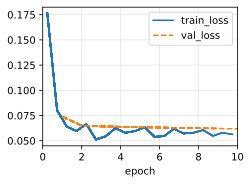

In [4]:
fijar_semilla()
model = d2l.LinearRegression(lr=0.01)
trainer = d2l.Trainer(max_epochs=10)
trainer.fit(model, data)

## 5. Predicción a un paso

Para cada instante se usan **observaciones reales** como entrada y se predice solo el valor siguiente. La predicción sigue muy bien a la serie incluso al final ($t=1000$): con datos reales en la entrada, el error no se acumula.

MSE a un paso en la parte de evaluación: 0.0621  (suelo teórico = 0.04)


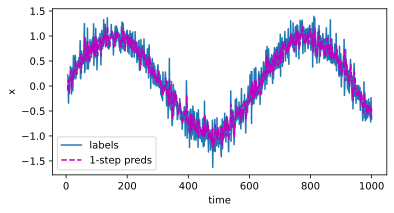

In [5]:
onestep_preds = model(data.features).detach().numpy()
d2l.plot(data.time[data.tau:], [data.labels, onestep_preds], 'time', 'x',
         legend=['labels', '1-step preds'], figsize=(6, 3))

mse_1paso = ((model(data.features[data.num_train:]) - data.labels[data.num_train:]) ** 2).mean().item()
print(f'MSE a un paso en la parte de evaluación: {mse_1paso:.4f}  (suelo teórico = 0.04)')

## 6. Predicción a varios pasos realimentando las propias predicciones

Si solo conociéramos la serie hasta $x_{604}$, no podríamos calcular directamente $\hat x_{609}$: faltan sus entradas. La solución es **realimentar**: cada predicción pasa a ser entrada de la siguiente,

$$\hat x_{605}=f(x_{601},x_{602},x_{603},x_{604}),\quad \hat x_{606}=f(x_{602},x_{603},x_{604},\hat x_{605}),\quad\dots,\quad \hat x_{609}=f(\hat x_{605},\dots,\hat x_{608}).$$

A partir de la quinta predicción el modelo ya **solo ve sus propias salidas**.

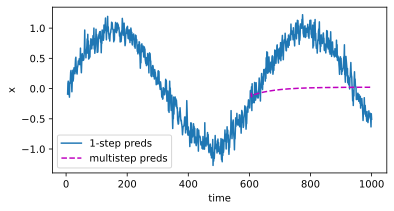

In [6]:
multistep_preds = torch.zeros(data.T)
multistep_preds[:] = data.x
for i in range(data.num_train + data.tau, data.T):
    multistep_preds[i] = model(
        multistep_preds[i - data.tau:i].reshape((1, -1)))
multistep_preds = multistep_preds.detach().numpy()

d2l.plot([data.time[data.tau:], data.time[data.num_train+data.tau:]],
         [onestep_preds, multistep_preds[data.num_train+data.tau:]], 'time',
         'x', legend=['1-step preds', 'multistep preds'], figsize=(6, 3))

La predicción realimentada **fracasa**: tras unos pocos pasos se aplana hacia una constante. Los errores se acumulan: si el primer paso comete un error $\epsilon_1=\bar\epsilon$, la entrada del segundo ya está perturbada y su error es del orden de $\epsilon_2=\bar\epsilon+c\,\epsilon_1$, y así sucesivamente. Es lo mismo que pasa con la previsión del tiempo: fiable a 24 horas, cada vez peor después.

## 7. Predicción a $k$ pasos

`k_step_pred(k)` calcula a la vez, para toda la serie, las predicciones a $1,2,\dots,k$ pasos: parte de $\tau$ columnas de datos reales y añade una columna nueva por paso, cada una calculada con las $\tau$ columnas anteriores. La columna $\tau+i$ guarda la predicción a $i+1$ pasos.

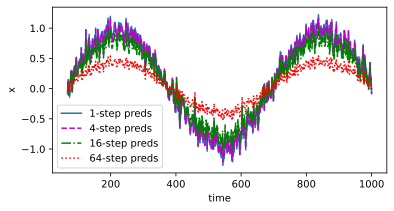

In [7]:
def k_step_pred(k):
    features = []
    for i in range(data.tau):
        features.append(data.x[i : i+data.T-data.tau-k+1])
    # The (i+tau)-th element stores the (i+1)-step-ahead predictions
    for i in range(k):
        preds = model(torch.stack(features[i : i+data.tau], 1))
        features.append(preds.reshape(-1))
    return features[data.tau:]


steps = (1, 4, 16, 64)
preds = k_step_pred(steps[-1])
d2l.plot(data.time[data.tau+steps[-1]-1:],
         [preds[k - 1].detach().numpy() for k in steps], 'time', 'x',
         legend=[f'{k}-step preds' for k in steps], figsize=(6, 3))

A 1 y 4 pasos la predicción es buena; a 16 empieza a suavizarse y a 64 pasos pierde amplitud (se «encoge» hacia cero). La calidad se degrada al alejarse en el futuro. En los ejercicios cuantificamos esta degradación con MSE en lugar de a ojo.

# Parte B — Ejercicios

## 8. Herramientas comunes

Para barrer muchos valores de $\tau$ y de semillas sin dibujar una curva de entrenamiento por modelo, se reimplementa en PyTorch puro la misma receta de `d2l.LinearRegression` + `d2l.Trainer`: capa `nn.Linear(tau, 1)`, SGD con $\eta=0{,}01$, MSE, lotes de 16 barajados y 10 épocas.

> **Detalle de d2l.** `LinearRegression` crea una `nn.LazyLinear(1)` y a continuación llama a `weight.data.normal_(0, 0.01)`. Pero una capa *lazy* no tiene pesos hasta la primera pasada hacia delante, así que esa línea **no tiene efecto**: los pesos se crean después con la inicialización por defecto de PyTorch, uniforme en $\pm1/\sqrt{\tau}$ (sesgo incluido). La réplica usa esa misma inicialización.

Decisiones de evaluación:

* **Partición fija por tiempo.** Las etiquetas $x_t$ con $t\le600$ entrenan y las de $t=601..1000$ evalúan, sea cual sea $\tau$. Así todos los modelos se comparan sobre **los mismos 400 valores** (en el cuaderno base la partición se movía con $\tau$). Nunca se baraja la serie antes de partirla: el futuro no puede entrenar al modelo que lo predice.
* **Solución exacta por mínimos cuadrados (MCO).** Como el modelo es lineal, el mínimo de la pérdida MSE tiene solución cerrada. Se calcula como referencia: si SGD se aleja de ella, el problema es de **optimización** (no ha convergido o diverge), no del modelo.
* **Métricas.** $\text{MSE}=\frac1n\sum(\hat x_t-x_t)^2$ y $\text{MAE}=\frac1n\sum|\hat x_t-x_t|$.

In [8]:
def crear_ventanas(x, tau, objetivos):
    """Para cada índice t de `objetivos`: X = x[t-tau : t] (tau valores previos) e y = x[t]."""
    objetivos = torch.as_tensor(objetivos)
    X = x[objetivos[:, None] + torch.arange(-tau, 0)]
    return X, x[objetivos].reshape(-1, 1)


def entrenar_ar_sgd(X, y, lr=0.01, epocas=10, batch_size=16, semilla=SEED):
    """Misma receta que d2l.LinearRegression + d2l.Trainer, sin gráficas."""
    torch.manual_seed(semilla)
    modelo = nn.Linear(X.shape[1], 1)          # inicialización por defecto, como la LazyLinear de d2l
    optimizador = torch.optim.SGD(modelo.parameters(), lr=lr)
    perdida = nn.MSELoss()
    loader = DataLoader(TensorDataset(X, y), batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(semilla))
    for _ in range(epocas):
        for Xb, yb in loader:
            optimizador.zero_grad()
            perdida(modelo(Xb), yb).backward()
            optimizador.step()
    return modelo.requires_grad_(False)


class ARMinimosCuadrados:
    """Autorregresión lineal ajustada por mínimos cuadrados (solución cerrada)."""

    def __init__(self, X, y):
        A = torch.cat([X, torch.ones(len(X), 1)], 1).double()
        solucion = torch.linalg.lstsq(A, y.double()).solution
        self.weight = solucion[:-1].T.float()
        self.bias = solucion[-1].float()

    def __call__(self, X):
        return X @ self.weight.T + self.bias


@torch.no_grad()
def predecir_k_pasos(modelo, x, tau, objetivos, k):
    """Predice x[t] para cada t de `objetivos` usando solo datos hasta t-k
    y realimentando las propias predicciones k veces."""
    objetivos = torch.as_tensor(objetivos)
    ventana = x[(objetivos - k)[:, None] + torch.arange(-tau + 1, 1)]   # x[t-k-tau+1 .. t-k]
    for _ in range(k):
        ventana = torch.cat([ventana, modelo(ventana[:, -tau:])], 1)
    return ventana[:, -1]


@torch.no_grad()
def prediccion_libre(modelo, x, tau, inicio):
    """Desde `inicio` en adelante, el modelo solo ve sus propias predicciones."""
    serie = x.clone()
    for t in range(inicio, len(x)):
        serie[t] = modelo(serie[t - tau:t].reshape(1, -1)).squeeze()
    return serie


def mse(a, b):
    return float(((torch.as_tensor(a).flatten() - torch.as_tensor(b).flatten()) ** 2).mean())


def mae(a, b):
    return float((torch.as_tensor(a).flatten() - torch.as_tensor(b).flatten()).abs().mean())


def generar_seno(semilla, T=1000):
    g = torch.Generator().manual_seed(semilla)
    tiempo = torch.arange(1, T + 1, dtype=torch.float32)
    limpia = torch.sin(0.01 * tiempo)
    return tiempo, limpia + torch.randn(T, generator=g) * 0.2, limpia


T, N_TRAIN = 1000, 600
IDX_TEST = torch.arange(N_TRAIN, T)          # etiquetas x_601 ... x_1000 (índices 600..999)

# Comprobación con los datos de la Parte A (tau = 4): d2l y réplica, 5 semillas cada uno
Xtr, ytr = crear_ventanas(data.x, 4, torch.arange(4, N_TRAIN))
Xte, yte = crear_ventanas(data.x, 4, IDX_TEST)
err_d2l, err_rep = [], []
for s in range(5):
    fijar_semilla(s)
    m_d2l = d2l.LinearRegression(lr=0.01)
    m_d2l.board.display = False                     # sin curva de entrenamiento
    d2l.Trainer(max_epochs=10).fit(m_d2l, data)
    err_d2l.append(mse(m_d2l(Xte).detach(), yte))
    err_rep.append(mse(entrenar_ar_sgd(Xtr, ytr, semilla=s)(Xte), yte))
print('MSE test d2l    :', np.round(err_d2l, 4), f'media {np.mean(err_d2l):.4f}')
print('MSE test réplica:', np.round(err_rep, 4), f'media {np.mean(err_rep):.4f}')
print(f'MSE test MCO    : {mse(ARMinimosCuadrados(Xtr, ytr)(Xte), yte):.4f}')

MSE test d2l    : [0.0622 0.0661 0.0613 0.0656 0.0744] media 0.0659
MSE test réplica: [0.0642 0.0642 0.0585 0.0569 0.062 ] media 0.0612
MSE test MCO    : 0.0572


La réplica y d2l dan errores del mismo orden (≈ 0,06) y ambos varían de una semilla a otra, porque cambian la inicialización y el orden de los lotes (d2l, además, usa una partición ligeramente distinta: entrena con las etiquetas $x_5..x_{604}$). Los dos quedan por encima de la solución exacta MCO (0,057): **10 épocas de SGD no bastan para llegar al mínimo**. Lo tendremos en cuenta al interpretar los resultados.

## 9. Ejercicio 1 — ¿Cuántas observaciones anteriores ($\tau$) usar?

Se prueban $\tau\in\{1,2,3,4,6,8,12,16,24,32,48,64\}$ con **10 semillas** (cada una genera un ruido distinto y una inicialización y un orden de lotes distintos). Para cada combinación se mide:

* MSE de entrenamiento y de test frente a la serie observada (con ruido);
* MSE de test frente a la **señal limpia** $\sin(0{,}01t)$: cuánto se aleja el modelo de la parte predecible;
* MAE de test y MSE de test de la solución MCO.

In [9]:
TAUS = [1, 2, 3, 4, 6, 8, 12, 16, 24, 32, 48, 64]
SEMILLAS = range(10)

filas = []
for tau in TAUS:
    for s in SEMILLAS:
        _, x, limpia = generar_seno(s)
        Xtr, ytr = crear_ventanas(x, tau, torch.arange(tau, N_TRAIN))
        Xte, yte = crear_ventanas(x, tau, IDX_TEST)
        m = entrenar_ar_sgd(Xtr, ytr, semilla=s)
        pred = m(Xte)
        filas.append({'tau': tau, 'semilla': s,
                      'mse_train': mse(m(Xtr), ytr), 'mse_test': mse(pred, yte),
                      'mse_senal': mse(pred, limpia[IDX_TEST]), 'mae_test': mae(pred, yte),
                      'mse_mco': mse(ARMinimosCuadrados(Xtr, ytr)(Xte), yte)})

res_tau = pd.DataFrame(filas)
tabla_tau = res_tau.groupby('tau').agg(
    mse_train=('mse_train', 'mean'), mse_test=('mse_test', 'mean'), std_test=('mse_test', 'std'),
    mse_senal=('mse_senal', 'mean'), mae_test=('mae_test', 'mean'), mse_mco=('mse_mco', 'mean'))
tabla_tau.round(4)

,mse_train,mse_test,std_test,mse_senal,mae_test,mse_mco
tau,,,,,,
1,0.0771,0.0790,0.0084,0.0376,0.2235,0.0792
2,0.0614,0.0635,0.0063,0.0220,0.2008,0.0608
3,0.0574,0.0577,0.0050,0.0169,0.1914,0.0543
4,0.0545,0.0554,0.0071,0.0141,0.1881,0.0518
6,0.0520,0.0537,0.0051,0.0123,0.1847,0.0486
8,0.0524,0.0527,0.0062,0.0125,0.1837,0.0473
12,0.0517,0.0521,0.0054,0.0116,0.1811,0.0467
16,0.0515,0.0534,0.0059,0.0124,0.1836,0.0469
24,0.0521,0.0555,0.0056,0.0143,0.1880,0.0472


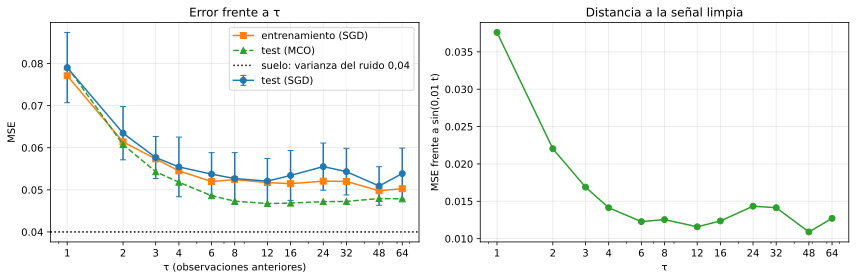

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
t_ = tabla_tau.index.values
ax[0].errorbar(t_, tabla_tau.mse_test, yerr=tabla_tau.std_test, marker='o', capsize=3, label='test (SGD)')
ax[0].plot(t_, tabla_tau.mse_train, marker='s', label='entrenamiento (SGD)')
ax[0].plot(t_, tabla_tau.mse_mco, marker='^', ls='--', label='test (MCO)')
ax[0].axhline(0.04, color='k', ls=':', label='suelo: varianza del ruido 0,04')
ax[0].set(xscale='log', xlabel='τ (observaciones anteriores)', ylabel='MSE', title='Error frente a τ')
ax[0].set_xticks(t_, t_)
ax[0].legend()
ax[1].plot(t_, tabla_tau.mse_senal, marker='o', color='tab:green')
ax[1].set(xscale='log', xlabel='τ', ylabel='MSE frente a sin(0,01 t)', title='Distancia a la señal limpia')
ax[1].set_xticks(t_, t_)
plt.tight_layout()
plt.show()

**Descomposición del error.** Como el ruido es independiente de la ventana, el MSE de test se reparte en dos sumandos:

$$\underbrace{\mathbb E\big[(\hat x_t-x_t)^2\big]}_{\text{MSE test}}=\underbrace{\mathbb E\big[(\hat x_t-\sin(0{,}01t))^2\big]}_{\text{error frente a la señal}}+\underbrace{0{,}2^2}_{\text{ruido: irreducible}}.$$

La tabla lo confirma: `mse_test` ≈ `mse_senal` + 0,04. Cuanto más pequeño es el error frente a la señal, más se acerca el modelo al suelo.

In [11]:
def tau_regla_1se(tabla, col='mse_test', col_std='std_test', n=len(SEMILLAS)):
    """Menor tau cuyo error medio está a menos de un error estándar del mejor."""
    mejor = tabla[col].idxmin()
    umbral = tabla.loc[mejor, col] + tabla.loc[mejor, col_std] / np.sqrt(n)
    return int(tabla.index[tabla[col] <= umbral].min()), int(mejor), umbral


TAU_ELEGIDO, tau_min, umbral = tau_regla_1se(tabla_tau)
print(f'τ con menor MSE medio: {tau_min} ({tabla_tau.loc[tau_min, "mse_test"]:.4f})')
print(f'Umbral (mejor + 1 error estándar): {umbral:.4f}')
print(f'τ más pequeño dentro del umbral: {TAU_ELEGIDO} ({tabla_tau.loc[TAU_ELEGIDO, "mse_test"]:.4f})')
mejora = 1 - tabla_tau.loc[TAU_ELEGIDO, 'mse_senal'] / tabla_tau.loc[4, 'mse_senal']
print(f'Frente a τ = 4, el error respecto a la señal baja un {100 * mejora:.0f} %')

τ con menor MSE medio: 48 (0.0509)
Umbral (mejor + 1 error estándar): 0.0524
τ más pequeño dentro del umbral: 12 (0.0521)
Frente a τ = 4, el error respecto a la señal baja un 18 %


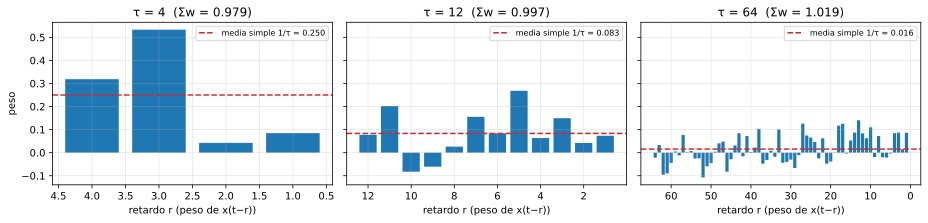

In [12]:
# ¿Qué aprende el modelo? Pesos (SGD, semilla 0) para tres valores de tau
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
_, x0, _ = generar_seno(0)
for a, tau in zip(ax, [4, TAU_ELEGIDO, 64]):
    Xtr, ytr = crear_ventanas(x0, tau, torch.arange(tau, N_TRAIN))
    w = entrenar_ar_sgd(Xtr, ytr, semilla=0).weight.flatten().numpy()
    retardos = np.arange(tau, 0, -1)                  # columna 0 = x_{t-tau}, última = x_{t-1}
    a.bar(retardos, w, color='tab:blue')
    a.axhline(1 / tau, color='tab:red', ls='--', label=f'media simple 1/τ = {1 / tau:.3f}')
    a.set(title=f'τ = {tau}  (Σw = {w.sum():.3f})', xlabel='retardo r (peso de x(t−r))')
    a.invert_xaxis()
    a.legend(fontsize=8)
ax[0].set_ylabel('peso')
plt.tight_layout()
plt.show()

### Conclusión del ejercicio 1

* **Con pocos valores ($\tau=1,2$) el error es alto** (MSE ≈ 0,079 y 0,061–0,064): la predicción copia casi el último valor observado, que lleva **todo su ruido** ($\sigma^2=0{,}04$) además del de la etiqueta.
* **Al aumentar $\tau$ el error cae rápido hasta $\tau\approx8$–$12$.** La solución exacta (MCO) baja de 0,079 a **0,0467 en $\tau=12$**, su mínimo, muy cerca del suelo de 0,04. Los pesos muestran por qué: se reparten por toda la ventana y suman ≈ 1, es decir, el modelo hace una especie de **media ponderada** de los últimos valores. Promediar $\tau$ valores reduce la varianza del ruido aproximadamente como $\sigma^2/\tau$, y como el seno cambia muy despacio (periodo ≈ 628 pasos), en una ventana corta la señal casi no varía.
* **Más allá de $\tau\approx12$ ya no se gana nada.** MCO incluso empeora un poco (0,048 con $\tau=48$–$64$): hay más parámetros que estimar con los mismos 600 ejemplos (**más varianza**) y ninguna información nueva.
* **SGD con la receta del curso queda ≈ 0,005 por encima de MCO** y oscila más de un $\tau$ a otro: 10 épocas desde una inicialización aleatoria no bastan para llegar al mínimo. Las diferencias entre los $\tau\ge6$ son del orden de la variación entre semillas (desviación ≈ 0,005), así que no son significativas.
* **Valor elegido: $\tau=12$.** Es el mínimo de MCO y también el $\tau$ **más pequeño** cuyo error SGD queda a menos de un error estándar del mejor (regla «1-SE»). Es el compromiso entre precisión y simplicidad: casi el mismo error que el mejor con menos parámetros, menos ejemplos perdidos al principio de la serie y menos riesgo de inestabilidad al realimentar (ver ejercicio 2).
* **Error de entrenamiento ≈ error de test** para todos los $\tau$: con un modelo lineal de pocos parámetros no hay sobreajuste apreciable.

## 10. Ejercicio 2 — Predicción a distintos horizontes $k$

Con el $\tau$ elegido se predice cada valor $x_t$ de la parte de test usando solo datos hasta $x_{t-k}$ y realimentando $k$ veces, para $k\in\{1,2,4,8,16,32,64\}$. Para comparar horizontes sobre **los mismos objetivos**, se evalúan las etiquetas $t=665..1000$ (así, incluso con $k=64$, la última observación real usada es de la zona de test). Se añaden $\tau=4$ y $\tau=64$ como contraste y dos referencias: el suelo del ruido (0,04) y predecir siempre 0 (la media de la serie).

In [13]:
KS = [1, 2, 4, 8, 16, 32, 64]
IDX_K = torch.arange(N_TRAIN + max(KS), T)
TAUS_K = sorted({4, TAU_ELEGIDO, 64})

filas = []
for tau in TAUS_K:
    for s in SEMILLAS:
        _, x, limpia = generar_seno(s)
        Xtr, ytr = crear_ventanas(x, tau, torch.arange(tau, N_TRAIN))
        m = entrenar_ar_sgd(Xtr, ytr, semilla=s)
        for k in KS:
            pred = predecir_k_pasos(m, x, tau, IDX_K, k)
            filas.append({'tau': tau, 'semilla': s, 'k': k,
                          'mse': mse(pred, x[IDX_K]), 'mae': mae(pred, x[IDX_K])})
res_k = pd.DataFrame(filas)
tabla_k = res_k.pivot_table(index='k', columns='tau', values=['mse', 'mae'], aggfunc='mean')
mse_cero = float((torch.stack([generar_seno(s)[1][IDX_K] for s in SEMILLAS]) ** 2).mean())
print(f'Referencia «predecir 0»: MSE = {mse_cero:.3f}')
tabla_k.round(3)

Referencia «predecir 0»: MSE = 0.512


mae                  mse              
tau     4      12     64     4      12     64
k                                            
1    0.187  0.179  0.184  0.054  0.051  0.053
2    0.188  0.180  0.185  0.056  0.051  0.054
4    0.189  0.182  0.186  0.057  0.052  0.054
8    0.192  0.185  0.190  0.057  0.054  0.057
16   0.218  0.205  0.205  0.072  0.065  0.066
32   0.287  0.270  0.261  0.121  0.108  0.110
64   0.441  0.456  0.506  0.261  0.278  0.442

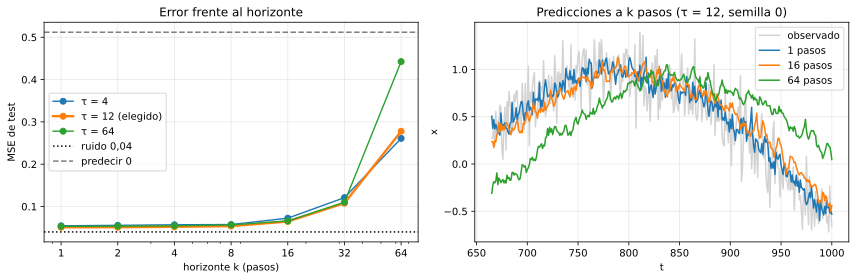

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for tau in TAUS_K:
    ax[0].plot(KS, tabla_k[('mse', tau)], marker='o', lw=2.4 if tau == TAU_ELEGIDO else 1.4,
               label=f'τ = {tau}' + (' (elegido)' if tau == TAU_ELEGIDO else ''))
ax[0].axhline(0.04, color='k', ls=':', label='ruido 0,04')
ax[0].axhline(mse_cero, color='gray', ls='--', label='predecir 0')
ax[0].set(xscale='log', xlabel='horizonte k (pasos)', ylabel='MSE de test', title='Error frente al horizonte')
ax[0].set_xticks(KS, KS)
ax[0].legend()

_, x0, limpia0 = generar_seno(0)
Xtr, ytr = crear_ventanas(x0, TAU_ELEGIDO, torch.arange(TAU_ELEGIDO, N_TRAIN))
m0 = entrenar_ar_sgd(Xtr, ytr, semilla=0)
ax[1].plot(IDX_K + 1, x0[IDX_K], color='lightgray', label='observado')
for k in (1, 16, 64):
    ax[1].plot(IDX_K + 1, predecir_k_pasos(m0, x0, TAU_ELEGIDO, IDX_K, k), label=f'{k} pasos')
ax[1].set(xlabel='t', ylabel='x', title=f'Predicciones a k pasos (τ = {TAU_ELEGIDO}, semilla 0)')
ax[1].legend()
plt.tight_layout()
plt.show()

### Predicción «libre» desde $t=601$

El caso extremo es la celda de la Parte A: a partir del final del entrenamiento el modelo no vuelve a ver ningún dato real. Un AR lineal realimentado es una **recurrencia lineal**, $\hat x_t=\sum_i w_i\hat x_{t-i}+b$, y su comportamiento a largo plazo depende solo de sus pesos:

* si los pesos suman algo menos de 1 (raíces del polinomio característico dentro del círculo unidad), la predicción **decae a la constante** $b/(1-\sum w_i)$: es lo que se veía en la Parte A;
* si suman algo más de 1, la predicción **deriva o explota**;
* solo si los pesos reproducen la dinámica del seno la predicción **oscila**.

Un cambio minúsculo en los pesos (Σw = 0,98 frente a 1,01) cambia por completo la trayectoria. Se mide con el radio espectral $\rho$ de la matriz compañera del AR: $\rho<1$ estable, $\rho>1$ inestable.

     suma_pesos    rho  mse_libre
tau                              
4         0.978  0.992      0.534
12        0.995  0.999      0.901
64        1.031  1.007      3.709


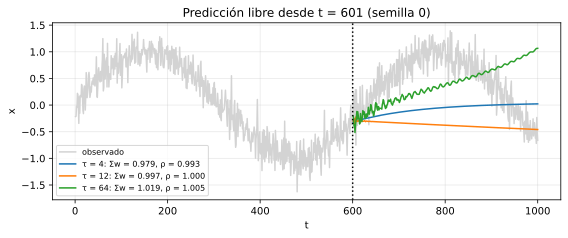

In [15]:
def radio_espectral(modelo):
    w = modelo.weight.flatten().double().numpy()[::-1]       # w[0] multiplica x_{t-1}
    tau = len(w)
    C = np.zeros((tau, tau))
    C[0] = w
    C[1:, :-1] = np.eye(tau - 1)
    return float(np.abs(np.linalg.eigvals(C)).max())


filas = []
for tau in TAUS_K:
    for s in SEMILLAS:
        _, x, _ = generar_seno(s)
        Xtr, ytr = crear_ventanas(x, tau, torch.arange(tau, N_TRAIN))
        m = entrenar_ar_sgd(Xtr, ytr, semilla=s)
        libre = prediccion_libre(m, x, tau, N_TRAIN)
        filas.append({'tau': tau, 'semilla': s, 'suma_pesos': float(m.weight.sum()),
                      'rho': radio_espectral(m), 'mse_libre': mse(libre[N_TRAIN:], x[N_TRAIN:])})
res_libre = pd.DataFrame(filas)
print(res_libre.groupby('tau')[['suma_pesos', 'rho', 'mse_libre']].median().round(3))

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(np.arange(1, T + 1), x0, color='lightgray', label='observado')
for tau in TAUS_K:
    Xtr, ytr = crear_ventanas(x0, tau, torch.arange(tau, N_TRAIN))
    m = entrenar_ar_sgd(Xtr, ytr, semilla=0)
    libre = prediccion_libre(m, x0, tau, N_TRAIN)
    ax.plot(np.arange(N_TRAIN + 1, T + 1), libre[N_TRAIN:],
            label=f'τ = {tau}: Σw = {float(m.weight.sum()):.3f}, ρ = {radio_espectral(m):.3f}')
ax.axvline(N_TRAIN, color='k', ls=':')
ax.set(xlabel='t', ylabel='x', title='Predicción libre desde t = 601 (semilla 0)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Conclusión del ejercicio 2

* **El error crece con el horizonte.** Con $\tau=12$ el MSE es 0,051 a un paso, apenas sube hasta $k=8$ (0,054: las entradas aún son casi todas datos reales), crece a partir de $k=16$ (0,065), se duplica en $k=32$ (0,108) y en $k=64$ llega a 0,278, **más de 5 veces el error a un paso** (aunque todavía mejor que predecir siempre 0, 0,51). La causa es la **acumulación de errores**: cada predicción realimentada arrastra el error de las anteriores.
* **Un $\tau$ mayor no arregla el largo plazo; puede empeorarlo.** Hasta $k=32$ los tres $\tau$ se comportan casi igual, pero en $k=64$ el modelo con $\tau=64$ es el peor (0,44): con 64 pesos es más fácil que la recurrencia quede ligeramente inestable ($\rho$ mediano 1,007) y las predicciones se desvíen.
* **La predicción libre depende de $\rho$:** con $\tau=4$ ($\rho<1$) decae a una constante; con $\tau=12$ ($\rho\approx1$) queda casi congelada en una recta; con $\tau=64$ ($\rho>1$) deriva. Ninguna reproduce el seno: el MSE libre mediano es 0,53, 0,90 y 3,7, peor que predecir 0.
* **Lección:** un modelo entrenado para predecir **un** paso no está optimizado para predecir muchos. Para horizontes largos hacen falta modelos que capten la dinámica completa (el estado de la serie), no solo una ventana: es la motivación de los modelos latentes y de las RNN de los próximos temas.

## 11. Ejercicio 3a — Datos reales: temperaturas mínimas diarias

Serie de temperaturas mínimas diarias (Melbourne, 1981–1990): 3 650 días, exactamente 365 por año (se omite el 31 de diciembre de los años bisiestos). Tiene **ciclo anual** (más frío en julio, hemisferio sur), mucha variabilidad de un día a otro y es aproximadamente estacionaria (no hay tendencia).

Preparación:

* **Partición temporal 70/30:** 1981–1987 (2 555 días) entrena; 1988–1990 (1 095 días) evalúa.
* **Estandarización** con media y desviación **del entrenamiento** (usar las de toda la serie filtraría información del test). Los errores se devuelven a °C.
* **Referencias ingenuas** que todo modelo debe batir:
  * **persistencia**: «mañana igual que hoy», $\hat x_t=x_{t-1}$;
  * **climatología**: la media de entrenamiento;
  * **estacional ingenua**: el mismo día del año anterior, $\hat x_t=x_{t-365}$.

(3650, 2) 1981-01-01 → 1990-12-31
{'count': 3650.0, 'mean': 11.18, 'std': 4.07, 'min': 0.0, '25%': 8.3, '50%': 11.0, '75%': 14.0, 'max': 26.3}


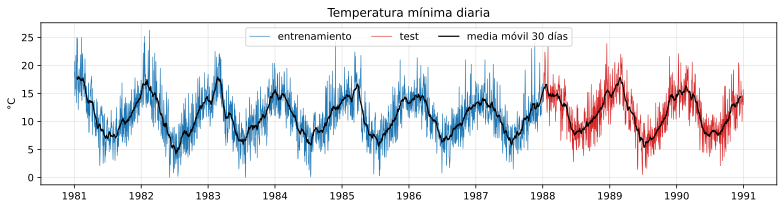

,MAE (°C),MSE (°C²)
persistencia (x(t−1)),2.012,6.666
climatología (media train),3.327,16.381
estacional (x(t−365)),3.016,14.407


In [16]:
temp = pd.read_csv(DATA_DIR / 'daily-min-temperatures.csv', parse_dates=['Date'])
print(temp.shape, temp.Date.min().date(), '→', temp.Date.max().date())
print(temp.Temp.describe().round(2).to_dict())

xt_raw = torch.tensor(temp.Temp.values, dtype=torch.float32)
N_T = len(xt_raw)
NTR_T = int(0.7 * N_T)
mu_t, sd_t = xt_raw[:NTR_T].mean(), xt_raw[:NTR_T].std()
xt = (xt_raw - mu_t) / sd_t
IDX_TEST_T = torch.arange(NTR_T, N_T)
y_test_t = xt_raw[IDX_TEST_T]

fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(temp.Date[:NTR_T], temp.Temp[:NTR_T], lw=0.6, label='entrenamiento')
ax.plot(temp.Date[NTR_T:], temp.Temp[NTR_T:], lw=0.6, color='tab:red', label='test')
ax.plot(temp.Date, temp.Temp.rolling(30, center=True).mean(), color='k', lw=1.2, label='media móvil 30 días')
ax.set(ylabel='°C', title='Temperatura mínima diaria')
ax.legend(ncol=3)
plt.tight_layout()
plt.show()

ref_t = {
    'persistencia (x(t−1))': xt_raw[IDX_TEST_T - 1],
    'climatología (media train)': torch.full_like(y_test_t, float(mu_t)),
    'estacional (x(t−365))': xt_raw[IDX_TEST_T - 365],
}
pd.DataFrame({n: {'MAE (°C)': mae(p, y_test_t), 'MSE (°C²)': mse(p, y_test_t)} for n, p in ref_t.items()}).T.round(3)

### Barrido de $\tau$

Se prueba desde 1 día hasta un año completo. Para cada $\tau$: SGD con la receta del curso (media de 3 semillas) y MCO.

In [17]:
def curvatura_lotes(X, batch_size=16, n_lotes=200, semilla=SEED):
    """Media del mayor autovalor de X_b^T X_b / B en lotes aleatorios (curvatura de la MSE por lote, sin el factor 2)."""
    g = torch.Generator().manual_seed(semilla)
    lam = [torch.linalg.eigvalsh(X[idx].T @ X[idx] / batch_size).max()
           for idx in (torch.randperm(len(X), generator=g)[:batch_size] for _ in range(n_lotes))]
    return float(torch.stack(lam).mean())


TAUS_T = [1, 2, 3, 5, 7, 14, 21, 30, 60, 90, 180, 365]
filas = []
for tau in TAUS_T:
    Xtr, ytr = crear_ventanas(xt, tau, torch.arange(tau, NTR_T))
    Xte, _ = crear_ventanas(xt, tau, IDX_TEST_T)
    sgd = [entrenar_ar_sgd(Xtr, ytr, semilla=s)(Xte) * sd_t + mu_t for s in range(3)]
    mco = ARMinimosCuadrados(Xtr, ytr)(Xte) * sd_t + mu_t
    lam_lote = curvatura_lotes(Xtr)
    filas.append({'tau': tau,
                  'MAE SGD': np.mean([mae(p, y_test_t) for p in sgd]),
                  'MSE SGD': np.mean([mse(p, y_test_t) for p in sgd]),
                  'MAE MCO': mae(mco, y_test_t), 'MSE MCO': mse(mco, y_test_t),
                  'λmax lote': lam_lote, '2·η·λmax': 2 * 0.01 * lam_lote})
tabla_temp = pd.DataFrame(filas).set_index('tau')
tabla_temp.round(3)

,MAE SGD,MSE SGD,MAE MCO,MSE MCO,λmax lote,2·η·λmax
tau,,,,,,
1,1.929,5.990,1.932,5.999,0.964,0.019
2,1.924,5.961,1.922,5.951,1.758,0.035
3,1.881,5.739,1.879,5.732,2.410,0.048
5,1.854,5.529,1.844,5.475,3.737,0.075
7,1.818,5.341,1.818,5.338,4.880,0.098
14,1.798,5.240,1.795,5.233,8.881,0.178
21,1.828,5.410,1.790,5.218,13.042,0.261
30,1.799,5.258,1.796,5.246,17.482,0.350
60,1.854,5.541,1.813,5.304,31.960,0.639


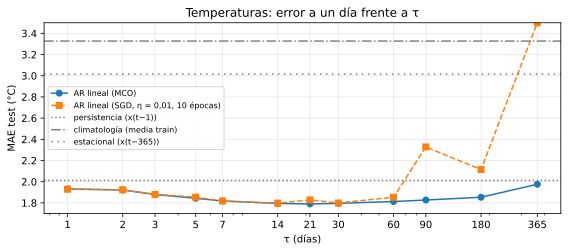

Mejor τ (MCO): 21 días → MAE = 1.790 °C, MSE = 5.218 °C²


In [18]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(TAUS_T, tabla_temp['MAE MCO'], marker='o', label='AR lineal (MCO)')
ax.plot(TAUS_T, tabla_temp['MAE SGD'].clip(upper=3.5), marker='s', ls='--', label='AR lineal (SGD, η = 0,01, 10 épocas)')
estilos = {'persistencia (x(t−1))': ':', 'climatología (media train)': '-.', 'estacional (x(t−365))': (0, (1, 3))}
for nombre, p in ref_t.items():
    ax.axhline(mae(p, y_test_t), color='gray', ls=estilos[nombre], label=nombre)
ax.set(xscale='log', xlabel='τ (días)', ylabel='MAE test (°C)', ylim=(1.7, 3.5), title='Temperaturas: error a un día frente a τ')
ax.set_xticks(TAUS_T, TAUS_T)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

TAU_T = int(tabla_temp['MAE MCO'].idxmin())
print(f'Mejor τ (MCO): {TAU_T} días → MAE = {tabla_temp.loc[TAU_T, "MAE MCO"]:.3f} °C, '
      f'MSE = {tabla_temp.loc[TAU_T, "MSE MCO"]:.3f} °C²')

**Por qué SGD falla con $\tau$ grande.** La pérdida MSE de un modelo lineal es una parábola cuya curvatura (hessiana) es $H=2X^\top X/n$. El descenso por gradiente con paso $\eta$ solo es estable si $\eta\,\lambda_{\max}(H)<2$; si no, cada paso «se pasa» del mínimo cada vez más. Con entradas estandarizadas y muy correlacionadas (la temperatura de días consecutivos se parece), $\lambda_{\max}$ crece casi proporcionalmente a $\tau$, y con lotes de 16 lo que cuenta es la curvatura de cada lote, aún mayor. La columna `2·η·λmax` estima $\eta\,\lambda_{\max}(H)$ por lote: con $\tau=365$ supera 2 y SGD **diverge** (su error se dispara). Con $\tau=90$–$180$ no diverge, pero 10 épocas no bastan para converger: las direcciones de curvatura pequeña avanzan muy despacio. MCO, que no depende del paso de aprendizaje, muestra el verdadero comportamiento del modelo.

### Horizontes $k$ con datos reales

Se comparan dos modelos MCO: el mejor a un día ($\tau$ elegido arriba) y uno con **un año de memoria** ($\tau=365$), frente a las referencias. La persistencia a $k$ días es $\hat x_t=x_{t-k}$.

In [19]:
KS_T = [1, 2, 3, 7, 14, 30, 60]
IDX_KT = torch.arange(NTR_T + max(KS_T), N_T)
y_kt = xt_raw[IDX_KT]
modelos_t = {}
for tau in (TAU_T, 365):
    Xtr, ytr = crear_ventanas(xt, tau, torch.arange(tau, NTR_T))
    modelos_t[tau] = ARMinimosCuadrados(Xtr, ytr)

filas = []
for k in KS_T:
    fila = {'k': k}
    for tau, m in modelos_t.items():
        fila[f'AR τ={tau}'] = mae(predecir_k_pasos(m, xt, tau, IDX_KT, k) * sd_t + mu_t, y_kt)
    fila['persistencia'] = mae(xt_raw[IDX_KT - k], y_kt)
    fila['estacional'] = mae(xt_raw[IDX_KT - 365], y_kt)
    fila['climatología'] = mae(torch.full_like(y_kt, float(mu_t)), y_kt)
    filas.append(fila)
tabla_kt = pd.DataFrame(filas).set_index('k')
print('MAE (°C) en función del horizonte k')
tabla_kt.round(3)

MAE (°C) en función del horizonte k


,AR τ=21,AR τ=365,persistencia,estacional,climatología
k,,,,,
1,1.795,1.981,2.029,2.979,3.252
2,2.034,2.242,2.599,2.979,3.252
3,2.089,2.283,2.770,2.979,3.252
7,2.147,2.312,2.777,2.979,3.252
14,2.271,2.350,2.926,2.979,3.252
30,2.506,2.417,3.032,2.979,3.252
60,3.067,2.417,3.820,2.979,3.252


Predicción libre 1988–1990 con τ = 21: MAE = 3.211 °C
Predicción libre 1988–1990 con τ = 365: MAE = 2.264 °C


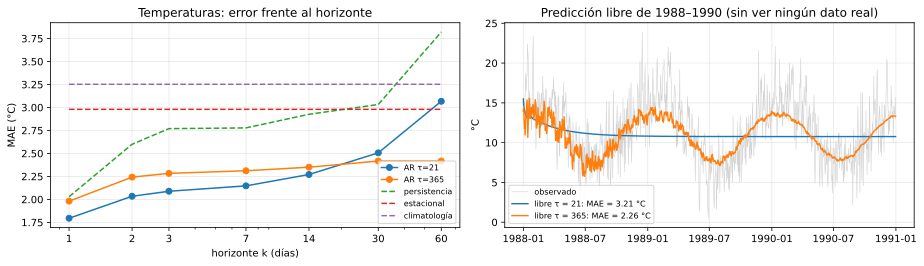

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for col in tabla_kt.columns:
    ls = '-' if col.startswith('AR') else '--'
    ax[0].plot(KS_T, tabla_kt[col], marker='o' if ls == '-' else None, ls=ls, label=col)
ax[0].set(xscale='log', xlabel='horizonte k (días)', ylabel='MAE (°C)', title='Temperaturas: error frente al horizonte')
ax[0].set_xticks(KS_T, KS_T)
ax[0].legend(fontsize=8)

fechas = temp.Date[NTR_T:]
ax[1].plot(fechas, y_test_t, color='lightgray', lw=0.6, label='observado')
mae_libre_t = {}
for tau, m in modelos_t.items():
    libre = prediccion_libre(m, xt, tau, NTR_T)[NTR_T:] * sd_t + mu_t
    mae_libre_t[tau] = mae(libre, y_test_t)
    ax[1].plot(fechas, libre, lw=1.4, label=f'libre τ = {tau}: MAE = {mae_libre_t[tau]:.2f} °C')
    print(f'Predicción libre 1988–1990 con τ = {tau}: MAE = {mae_libre_t[tau]:.3f} °C')
ax[1].set(ylabel='°C', title='Predicción libre de 1988–1990 (sin ver ningún dato real)')
ax[1].xaxis.set_major_locator(plt.matplotlib.dates.MonthLocator(bymonth=(1, 7)))
ax[1].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%Y-%m'))
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Conclusiones con temperaturas

* **A un día, el AR lineal bate a todas las referencias.** El mejor $\tau$ es de **21 días** (con 14 días el resultado es prácticamente igual): MAE = 1,79 °C y MSE = 5,22 °C², frente a 2,01 °C / 6,67 °C² de la persistencia, 3,02 °C de la estacional y 3,33 °C de la climatología. Mejora la persistencia un 11 % en MAE y un 22 % en MSE porque combina varios días (suaviza el ruido diario) y tiende a volver hacia la media.
* **La curva de error frente a $\tau$ tiene forma de U suave**: de 1 a 21 días mejora; a partir de 30 empeora poco a poco (1,98 °C con $\tau=365$): más parámetros, más varianza, y la información útil para mañana está en los días recientes.
* **El horizonte lo cambia todo.** Con $\tau=21$ el MAE pasa de 1,80 °C ($k=1$) a 2,27 °C ($k=14$) y 3,07 °C ($k=60$). A 60 días ya es peor que la estacional ingenua (2,98 °C) y apenas mejora la climatología (3,25 °C). Su predicción libre se aplana en la media en pocas semanas (MAE 3,21 °C en 1988–1990), igual que en el seno.
* **Con $\tau=365$ el modelo «recuerda» el año anterior.** Es peor a un día (1,98 °C) pero a partir de $k\approx30$ es el mejor de todos (2,42 °C), y su predicción libre **reproduce el ciclo estacional** durante tres años (MAE 2,26 °C frente a 3,21 °C). Para captar dependencias largas, un AR de ventana fija necesita una ventana enorme (365 parámetros).
* **Optimización:** con la receta del curso, SGD coincide con MCO hasta $\tau\approx30$; con $\tau=90$–$180$ no converge en 10 épocas y con $\tau=365$ diverge ($\eta\lambda_{\max}\approx2{,}5>2$, MAE 6,7 °C). Con ventanas largas hay que bajar la tasa de aprendizaje, entrenar más o usar la solución cerrada.

## 12. Ejercicio 3b — Complemento: cotización de IBM

Se repite el análisis con el precio de cierre diario de IBM de 2010 a 2017 (1 980 sesiones; partición 70/30). Una cotización bursátil se comporta de forma muy distinta a una temperatura: no tiene un nivel al que volver y, si el mercado es eficiente, el precio de mañana es el de hoy más un cambio impredecible (**paseo aleatorio**).

In [21]:
ibm = pd.read_csv(DATA_DIR / 'ibm.us.txt', parse_dates=['Date'])
ibm = ibm[ibm.Date >= '2010-01-01'].reset_index(drop=True)
xi_raw = torch.tensor(ibm.Close.values, dtype=torch.float32)
N_I = len(xi_raw)
NTR_I = int(0.7 * N_I)
mu_i, sd_i = xi_raw[:NTR_I].mean(), xi_raw[:NTR_I].std()
xi = (xi_raw - mu_i) / sd_i
IDX_TEST_I = torch.arange(NTR_I, N_I)
y_test_i = xi_raw[IDX_TEST_I]
print(f'{N_I} sesiones, entrenamiento hasta {ibm.Date[NTR_I - 1].date()}, precio en test entre '
      f'{y_test_i.min():.0f} y {y_test_i.max():.0f} USD')

filas = []
for tau in [1, 2, 5, 10, 20, 60]:
    Xtr, ytr = crear_ventanas(xi, tau, torch.arange(tau, NTR_I))
    Xte, _ = crear_ventanas(xi, tau, IDX_TEST_I)
    sgd = [entrenar_ar_sgd(Xtr, ytr, semilla=s)(Xte) * sd_i + mu_i for s in range(3)]
    mco_i = ARMinimosCuadrados(Xtr, ytr)
    pred = mco_i(Xte) * sd_i + mu_i
    filas.append({'tau': tau, 'MAE SGD': np.mean([mae(p, y_test_i) for p in sgd]),
                  'MAE MCO': mae(pred, y_test_i), 'MSE MCO': mse(pred, y_test_i),
                  'peso de x(t−1) (MCO)': float(mco_i.weight[0, -1])})
filas.append({'tau': 'persistencia', 'MAE MCO': mae(xi_raw[IDX_TEST_I - 1], y_test_i),
              'MSE MCO': mse(xi_raw[IDX_TEST_I - 1], y_test_i)})
pd.DataFrame(filas).set_index('tau').round(3)

1980 sesiones, entrenamiento hasta 2015-07-07, precio en test entre 110 y 177 USD


,MAE SGD,MAE MCO,MSE MCO,peso de x(t−1) (MCO)
tau,,,,
1,1.171,1.170,2.995,0.996
2,1.399,1.170,2.994,0.998
5,1.786,1.173,2.995,0.998
10,1.804,1.186,3.027,0.996
20,1.726,1.194,3.044,0.996
60,1.894,1.211,3.125,0.994
persistencia,NaN,1.174,3.001,NaN


In [22]:
TAU_I = 5
Xtr, ytr = crear_ventanas(xi, TAU_I, torch.arange(TAU_I, NTR_I))
mco_i = ARMinimosCuadrados(Xtr, ytr)
print('Pesos MCO (x(t−5) … x(t−1)):', mco_i.weight.flatten().numpy().round(3))

KS_I = [1, 2, 5, 10, 20, 60]
IDX_KI = torch.arange(NTR_I + max(KS_I), N_I)
tabla_ki = pd.DataFrame([{
    'k': k,
    'AR τ=5': mae(predecir_k_pasos(mco_i, xi, TAU_I, IDX_KI, k) * sd_i + mu_i, xi_raw[IDX_KI]),
    'persistencia': mae(xi_raw[IDX_KI - k], xi_raw[IDX_KI]),
} for k in KS_I]).set_index('k')
print('MAE (USD) en función del horizonte k')
print(tabla_ki.round(2))

# ¿Hay algo predecible en los cambios diarios? AR sobre rentabilidades
r = torch.diff(torch.log(xi_raw))
NTR_R = NTR_I - 1
rs = (r - r[:NTR_R].mean()) / r[:NTR_R].std()
Xtr, ytr = crear_ventanas(rs, 5, torch.arange(5, NTR_R))
Xte, yte = crear_ventanas(rs, 5, torch.arange(NTR_R, len(r)))
print(f'\nRentabilidades diarias estandarizadas: MSE AR(5) = {mse(ARMinimosCuadrados(Xtr, ytr)(Xte), yte):.3f} '
      f'| MSE prediciendo 0 = {mse(torch.zeros_like(yte), yte):.3f}')

Pesos MCO (x(t−5) … x(t−1)): [ 0.019  0.015 -0.053  0.016  0.998]
MAE (USD) en función del horizonte k
    AR τ=5  persistencia
k                       
1     1.11          1.12
2     1.64          1.64
5     2.69          2.72
10    3.81          3.88
20    5.83          5.99
60   10.98         11.84

Rentabilidades diarias estandarizadas: MSE AR(5) = 1.102 | MSE prediciendo 0 = 1.101


### Conclusiones con IBM

* **El AR lineal no mejora la persistencia**: MAE ≈ 1,17 USD en ambos casos a un día. Los pesos MCO se concentran en $x_{t-1}$ (≈ 1) y el resto es casi cero: el modelo **ha redescubierto la persistencia**. Más días de historia no añaden información (el error incluso sube un poco con $\tau$ grande).
* **A $k$ días el error crece de forma parecida a $\sqrt k$** (1,1 USD → 2,7 USD a 5 días → 5,8 USD a 20 días), el comportamiento típico de un paseo aleatorio, en el que la incertidumbre se acumula con el horizonte.
* **Las rentabilidades diarias no son predecibles** con un AR lineal: su MSE coincide con el de predecir siempre 0.
* **SGD con la receta del curso queda por detrás de MCO** incluso con $\tau$ pequeño: con 10 épocas no llega a la solución «peso 1 en el último día» partiendo de pesos casi nulos.
* **Contraste con las temperaturas**: la temperatura tiene una dinámica que el pasado explica en parte (inercia, estacionalidad) y un AR la aprovecha; una cotización es casi un paseo aleatorio y el mejor predictor sencillo es el último valor. **El error de un modelo solo tiene sentido comparado con una referencia ingenua.**

## 13. Ejercicio 4 — Modelos autorregresivos frente a modelos autorregresivos latentes

**Modelo autorregresivo (AR).** Predice directamente a partir de una **ventana fija** de observaciones:

$$\hat x_t = f(x_{t-1},\dots,x_{t-\tau}).$$

Es un problema supervisado con un número fijo de características. Su límite está en la **condición de Markov de orden $\tau$**: supone que lo anterior a $x_{t-\tau}$ no aporta nada. Si una dependencia es más larga que la ventana, el modelo no la puede ver; y si se agranda la ventana, crecen los parámetros y los datos necesarios.

**Modelo autorregresivo latente.** Mantiene un **resumen** del pasado, un estado oculto $h_t$ que no se observa, y lo actualiza en cada paso:

$$h_t = g(h_{t-1}, x_{t-1}),\qquad \hat x_t = P(x_t\mid h_t).$$

El tamaño de $h_t$ es fijo, pero en principio puede guardar información de **todo** el pasado, no solo de las últimas $\tau$ observaciones. Es la idea que implementan las **RNN** (tema siguiente): $h_t$ es el vector de estado de la red.

| | AR (ventana fija) | AR latente (estado oculto) |
|---|---|---|
| Entrada | $\tau$ observaciones | observación actual + estado $h_{t-1}$ |
| Memoria | exactamente $\tau$ pasos | potencialmente ilimitada, comprimida en $h_t$ |
| Parámetros | crecen con $\tau$ | no dependen de la longitud de la historia |
| Supuesto | Markov de orden $\tau$ en $x$ | Markov de orden 1 en el **estado** $h$ |
| Ejemplo | regresión lineal del lab | RNN, LSTM, filtro de Kalman, HMM |

### Ejemplos que necesitan variables latentes

1. **El propio ejercicio 3: la estación del año.** Para que la predicción libre de temperaturas reprodujera el ciclo anual, el AR necesitó $\tau=365$ entradas y 365 pesos. Lo que determina la temperatura esperada es una variable **no observada directamente**: la fase del año (y, a otra escala, la situación meteorológica: un frente frío, un anticiclón). Un modelo latente puede llevar esa información en un estado de dimensión muy pequeña (por ejemplo, dos números $\cos\varphi_t,\sin\varphi_t$ que avanzan cada día) en vez de memorizar un año entero de datos.
2. **Lenguaje.** En «Las llaves que dejé ayer encima de la mesa del salón **están**…», la concordancia del verbo depende de «llaves», muchas palabras atrás. El número de palabras intermedias no está acotado, así que ninguna ventana fija sirve siempre. Un estado latente puede guardar «sujeto plural pendiente» durante toda la frase. Lo mismo con paréntesis anidados: para saber si toca cerrar uno hay que **contar** cuántos quedan abiertos, y ese contador es una variable latente de un solo número.
3. **Regímenes ocultos en finanzas.** La volatilidad de una acción alterna entre épocas tranquilas y de crisis; el régimen no se observa, pero determina cuánto se moverá el precio. Los modelos de cambio de régimen (modelos ocultos de Markov) o de volatilidad estocástica tratan el régimen como variable latente que se infiere a partir de toda la historia.

En todos los casos, lo que hace falta recordar no es «los últimos $\tau$ valores» sino **un hecho del pasado, quizá lejano, que sigue siendo relevante**: un estado oculto lo resume y lo arrastra en el tiempo.

## 14. Resumen de resultados y conclusiones generales

In [23]:
import json

resumen = {
    'seno_tau': {int(t): {k: float(v) for k, v in fila.items()} for t, fila in tabla_tau.iterrows()},
    'seno_tau_elegido': TAU_ELEGIDO,
    'seno_k': {f'tau{t}': {int(k): float(tabla_k[('mse', t)][k]) for k in KS} for t in TAUS_K},
    'seno_k_mae': {f'tau{t}': {int(k): float(tabla_k[('mae', t)][k]) for k in KS} for t in TAUS_K},
    'seno_mse_cero': mse_cero,
    'seno_libre': res_libre.groupby('tau')[['suma_pesos', 'rho', 'mse_libre']].median().to_dict(),
    'temp_tau': {int(t): {k: float(v) for k, v in fila.items()} for t, fila in tabla_temp.iterrows()},
    'temp_tau_elegido': TAU_T,
    'temp_ref': {n: {'mae': mae(p, y_test_t), 'mse': mse(p, y_test_t)} for n, p in ref_t.items()},
    'temp_k': {c: {int(k): float(v) for k, v in tabla_kt[c].items()} for c in tabla_kt.columns},
    'temp_libre': {int(t): v for t, v in mae_libre_t.items()},
    'ibm_k': {c: {int(k): float(v) for k, v in tabla_ki[c].items()} for c in tabla_ki.columns},
}
with open(DATA_DIR / 'resultados_lab0.json', 'w', encoding='utf-8') as f:
    json.dump(resumen, f, ensure_ascii=False, indent=1)
print('Resultados guardados en resultados_lab0.json')

Resultados guardados en resultados_lab0.json


* **Un AR convierte una serie en un problema supervisado** mediante ventanas deslizantes de longitud $\tau$; con un modelo lineal es la autorregresión lineal de las diapositivas, y se puede entrenar con SGD o resolver por mínimos cuadrados.
* **Elegir $\tau$ es un compromiso**: muy pequeño no filtra el ruido; muy grande añade parámetros y varianza sin información nueva. En el seno el error cae hasta $\tau\approx8$–$12$ y se estabiliza cerca del suelo del ruido (0,04); en temperaturas el óptimo a un día ronda las 2–3 semanas.
* **Predecir a un paso es fácil; a muchos pasos, difícil.** Al realimentar las predicciones los errores se acumulan y el AR lineal tiende a su punto fijo (la media) o, si es inestable, diverge.
* **Hay que comparar siempre con referencias ingenuas** (persistencia, media, estacional). Las temperaturas tienen estructura que un AR aprovecha; la bolsa es casi un paseo aleatorio y el AR se reduce a la persistencia.
* **Las dependencias largas exigen ventanas enormes** en un AR (τ = 365 para la estacionalidad). Los **modelos latentes** (RNN, LSTM) resuelven esto con un estado oculto que resume el pasado: son el siguiente paso del curso.